# 🎓 ULK Fees Assistant: Notebook

This notebook goes with the **ULK Fees Assistant** Streamlit chatbot. You can use it to:

1. **Explore** the knowledge base (`knowledge_base.json`) as tables
2. **Test** the chatbot engine and its conversation memory
3. **Chat** with the bot inside the notebook
4. **Validate and update** the knowledge base (for example, add new aliases or next year's fees)
5. **Run the Streamlit app** from here, including on Google Colab

> Put this notebook in the same folder as `app.py`, `chatbot_engine.py` and `knowledge_base.json`.

## 1. Setup

In [1]:
# Install dependencies (needed on Colab / a fresh environment)
%pip install -q streamlit openai pandas ipywidgets


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
# --- Google Colab only: upload ulk-chatbot.zip, then unzip ---
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import files
    print("Upload ulk-chatbot.zip …")
    files.upload()
    !unzip -o -q ulk-chatbot.zip
    %cd ulk-chatbot
print("Working directory:", os.getcwd())
print("Files:", sorted(f for f in os.listdir('.') if not f.startswith('.')))

Working directory: /home/user/ulk-chatbot
Files: ['README.md', 'ULK_Fees_Chatbot.ipynb', 'app.py', 'assets', 'chatbot_engine.py', 'knowledge_base.json', 'requirements.txt']


## 2. Load the knowledge base (the bot's memory)

In [3]:
import json
import pandas as pd
from pathlib import Path

pd.set_option("display.max_colwidth", 120)
KB_FILE = Path("knowledge_base.json")
kb = json.loads(KB_FILE.read_text(encoding="utf-8"))

print("Title     :", kb["meta"]["title"])
print("Issued    :", kb["meta"]["issued"])
print("Sections  :", list(kb.keys()))
print(f"Programmes: {len(kb['programs'])} | Non-tuition fees: {len(kb['non_tuition_fees'])} | "
      f"Intents: {len(kb['intents'])} | FAQs: {len(kb['faqs'])}")
print("\nGeneral notes:")
for n in kb["general_notes"]:
    print(" •", n)

Title     : ULK Fees Structure for the Academic Year 2026-2027 (Year Ones Only)
Issued    : Done at ULK, March 01, 2026
Sections  : ['meta', 'school', 'general_notes', 'levels', 'schools', 'programs', 'graduation_fees', 'non_tuition_fees', 'bank_accounts', 'intents', 'faqs', 'fallback']
Programmes: 49 | Non-tuition fees: 38 | Intents: 4 | FAQs: 4

General notes:
 • This fees structure applies to Year One (new) students for the academic year 2026-2027.
 • There is no change of fees (tuition and other fees) for ongoing students (Year 2, 3 and 4).
 • All fees are the same for both national and international students.


## 3. Explore the data
### 3.1 Programmes overview

In [4]:
levels = kb["levels"]
programs_df = pd.DataFrame([{
    "Level": levels[p["level"]],
    "School": p["school"],
    "Programme": p["name"],
    "Duration": p["duration"],
    "Fee unit": p["tuition"]["unit"],
} for p in kb["programs"]])
programs_df.groupby("Level").size().rename("Programmes").to_frame()

,Programmes
Level,
PhD,3
Postgraduate (Master's),16
UPI Advanced Diploma,4
UPI Bachelor of Technology (B-Tech),4
Undergraduate (Bachelor's),22


In [5]:
programs_df

,Level,School,Programme,Duration,Fee unit
0,Undergraduate (Bachelor's),School of Economics and Business Studies,BBA in Banking,4 years,term
1,Undergraduate (Bachelor's),School of Economics and Business Studies,BBA in Insurance & Risk Management,4 years,term
2,Undergraduate (Bachelor's),School of Economics and Business Studies,BBA in Project Management,4 years,term
3,Undergraduate (Bachelor's),School of Economics and Business Studies,BBA in Procurement & Supply Chain Management,4 years,term
4,Undergraduate (Bachelor's),School of Economics and Business Studies,BBA in Business Information Technology,4 years,term
5,Undergraduate (Bachelor's),School of Economics and Business Studies,Accounting,3 years,term
6,Undergraduate (Bachelor's),School of Economics and Business Studies,Economics,3 years,term
7,Undergraduate (Bachelor's),School of Economics and Business Studies,Finance,3 years,term
8,Undergraduate (Bachelor's),School of Social Sciences,Development Studies,3 years,term
9,Undergraduate (Bachelor's),School of Social Sciences,International Relations,3 years,term


### 3.2 Undergraduate tuition by campus and schedule

In [6]:
ug_rows = []
for p in kb["programs"]:
    if p["tuition"]["unit"] == "term":
        for r in p["tuition"]["rates"]:
            ug_rows.append({"School": p["school"], "Programme": p["name"], "Campus": r["campus"],
                            "Schedule": r["schedule"], "Per term": r["per_term"], "Per year": r["per_year"]})
ug_df = pd.DataFrame(ug_rows)
ug_pivot = ug_df.pivot_table(index=["School", "Programme"], columns=["Campus", "Schedule"],
                             values="Per term", aggfunc="first")
ug_pivot.style.format("{:,.0f}", na_rep="—")

### 3.3 UPI, Master's and PhD

In [7]:
upi_df = pd.DataFrame([{"Level": levels[p["level"]], "Programme": p["name"], "Schedule": r["schedule"],
                        "Per year (Rwf)": r["per_year"], "Duration": p["duration"]}
                       for p in kb["programs"] if p["tuition"]["unit"] == "year" for r in p["tuition"]["rates"]])
upi_df.style.format({"Per year (Rwf)": "{:,.0f}"})

,Level,Programme,Schedule,Per year (Rwf),Duration
0,UPI Advanced Diploma,Advanced Diploma in Electrical Technology,Day,"690,000",3 years
1,UPI Advanced Diploma,Advanced Diploma in Electrical Technology,Evening,"750,000",3 years
2,UPI Advanced Diploma,Advanced Diploma in Electronics and Telecommunication,Day,"690,000",3 years
3,UPI Advanced Diploma,Advanced Diploma in Electronics and Telecommunication,Evening,"750,000",3 years
4,UPI Advanced Diploma,Advanced Diploma in Construction Technology,Day,"690,000",3 years
5,UPI Advanced Diploma,Advanced Diploma in Construction Technology,Evening,"750,000",3 years
6,UPI Advanced Diploma,Advanced Diploma in Land Survey Engineering,Day,"690,000",3 years
7,UPI Advanced Diploma,Advanced Diploma in Land Survey Engineering,Evening,"750,000",3 years
8,UPI Bachelor of Technology (B-Tech),B-Tech in Electrical Technology,Day (44 weeks),"1,200,000",1 year
9,UPI Bachelor of Technology (B-Tech),B-Tech in Electrical Technology,Evening (53 weeks),"1,200,000",1 year


In [8]:
masters_df = pd.DataFrame([{"Programme": p["name"], "Modules": p["tuition"]["modules"],
                            "Per module (Rwf)": p["tuition"]["per_module"],
                            "Estimated total (Rwf)": p["tuition"]["estimated_total"]}
                           for p in kb["programs"] if p["level"] == "masters"])
masters_df.style.format({"Per module (Rwf)": "{:,.0f}", "Estimated total (Rwf)": "{:,.0f}"})

,Programme,Modules,Per module (Rwf),Estimated total (Rwf)
0,Master of Business Administration,10,"160,000","1,600,000"
1,Master of Finance,10,"160,000","1,600,000"
2,Master of Accounting,10,"160,000","1,600,000"
3,Master of Science in Economics,10,"160,000","1,600,000"
4,Master of Governance,10,"160,000","1,600,000"
5,Master of Development Studies,10,"160,000","1,600,000"
6,Master of Public International Law,10,"160,000","1,600,000"
7,Master of International Economic and Business Law,10,"160,000","1,600,000"
8,Master of Science in Internet Systems,10,"160,000","1,600,000"
9,MBA: Finance,16,"160,000","2,560,000"


In [9]:
phd_df = pd.DataFrame([{"Programme": p["name"], "Per semester": p["tuition"]["per_semester"],
                        "Per year": p["tuition"]["per_year"], "Application fee": p["application_fee"],
                        "Admission fee": p["admission_fee"]} for p in kb["programs"] if p["level"] == "phd"])
phd_df.style.format("{:,.0f}", subset=phd_df.columns[1:])

,Programme,Per semester,Per year,Application fee,Admission fee
0,PhD in Business Administration - Accounting,"1,500,000","3,000,000","100,000","100,000"
1,PhD in Business Administration - Finance,"1,500,000","3,000,000","100,000","100,000"
2,PhD in Business Administration - Management,"1,500,000","3,000,000","100,000","100,000"


### 3.4 Non-tuition fees, graduation fees and bank accounts

In [10]:
nt_df = pd.DataFrame(kb["non_tuition_fees"])[["name", "amount", "comment"]]
nt_df.columns = ["Fee", "Amount (Rwf)", "Comment"]
nt_df.style.format({"Amount (Rwf)": "{:,.0f}"})

,Fee,Amount (Rwf),Comment
0,Application fees,"10,000",
1,"Registration fees (student card, file, documents scanning services & life insurance included)","45,000",
2,Student card (duplicate),"10,000",
3,Retake fees,"50,000",
4,Supplementary exam fee,"30,000",Per assessment
5,Degree - duplicate,"40,000",
6,Academic transcript,"15,000",
7,Academic transcript (translation),"10,000",
8,Attendance testimonial,"10,000",
9,Certificate of completion of all modules,"15,000",Concerns students in final year waiting for graduation


In [11]:
grad = kb["graduation_fees"]
display(pd.DataFrame([{"Level": levels[k], "Supervision, Degree & Gown (Rwf)": v}
                      for k, v in grad["by_level"].items()]))
display(pd.DataFrame([{"Campus": c, **a} for c, lst in kb["bank_accounts"].items() for a in lst]))

,Level,"Supervision, Degree & Gown (Rwf)"
0,Undergraduate (Bachelor's),250000
1,UPI Advanced Diploma,250000
2,UPI Bachelor of Technology (B-Tech),360000
3,Postgraduate (Master's),360000


,Campus,bank,account
0,Kigali,Equity Bank,4012211287137
1,Kigali,Bank of Kigali,00040-00201556-23
2,Kigali,Unguka Bank,10100460240010
3,Kigali,I&M Bank,20014031001
4,Gisenyi,Equity Bank,4006211289277
5,Gisenyi,Bank of Kigali,000530066946623
6,Gisenyi,Unguka Bank,30400466900014
7,Gisenyi,I&M Bank,20014031002


### 3.5 Quick chart: yearly undergraduate tuition (Kigali vs Gisenyi, Day)

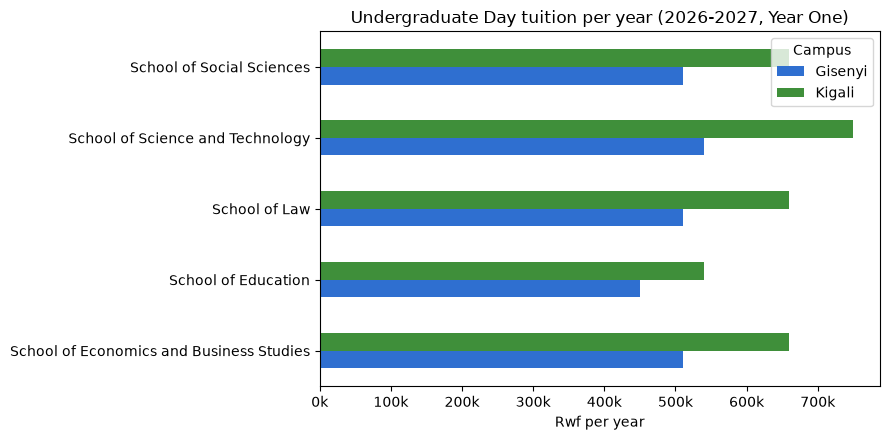

In [12]:
import matplotlib.pyplot as plt
day = ug_df[ug_df["Schedule"].isin(["Day", "Day & Holidays"])]
chart = day.groupby(["School", "Campus"])["Per year"].max().unstack()
ax = chart.plot(kind="barh", figsize=(9, 4.5), color=["#2f6fd0", "#3f8f3a"])
ax.set_xlabel("Rwf per year"); ax.set_ylabel("")
ax.set_title("Undergraduate Day tuition per year (2026-2027, Year One)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:,.0f}k"))
plt.tight_layout(); plt.show()

## 4. Test the chatbot engine
The engine (`chatbot_engine.py`) matches each question against the JSON and builds a Markdown answer.

In [13]:
import importlib, chatbot_engine
importlib.reload(chatbot_engine)
from chatbot_engine import FeesBot, Memory
from IPython.display import Markdown, display

bot = FeesBot("knowledge_base.json")

def ask(question, memory=None, show_debug=True):
    answer, info = bot.answer(question, memory or Memory())
    display(Markdown(f"**🧑‍🎓 {question}**"))
    if show_debug:
        print("detected →", {k: v for k, v in info.items() if v})
    display(Markdown(answer))
    display(Markdown("---"))

ask("How much is Software Engineering evening in Kigali?")

**🧑‍🎓 How much is Software Engineering evening in Kigali?**

detected → {'campus': 'Kigali', 'schedule': 'Evening', 'programs': ['ug_software_engineering']}


Showing results for campus **Kigali** and schedule **Evening**:

### 🎓 Software Engineering
**Undergraduate (Bachelor's)** · School of Science and Technology

⏱️ **Duration:** 4 years

| Campus | Schedule | Per term | Per year | Full programme (est.) |
|---|---|---|---|---|
| Kigali | Evening | **270,000 Rwf** | 810,000 Rwf | 3,240,000 Rwf (4 yrs) |

➕ Supervision, Degree & Gown fees: **250,000 Rwf** (not refundable)  
➕ Application: 10,000 Rwf · Registration: 45,000 Rwf

ℹ️ _Fees apply to Year One students for 2026–2027. Ongoing students (Year 2–4): no change. Same fees for national & international students._

🔎 **Related programmes:** *Master of Science in Software Engineering* — just ask!

---

In [14]:
for q in ["transcript fee", "Bank accounts for Gisenyi", "Are fees the same for international students?",
          "MBA marketing", "graduation gown fees"]:
    ask(q)

**🧑‍🎓 transcript fee**

detected → {'items': ['transcript']}


### 🧾 Other (non-tuition) fees

| Fee | Amount | Notes |
|---|---|---|
| Academic transcript | **15,000 Rwf** | — |

---

**🧑‍🎓 Bank accounts for Gisenyi**

detected → {'campus': 'Gisenyi'}


... (10 outputs left out)

**🧑‍🎓 graduation gown fees**

detected → {'items': ['__graduation__']}


### 🎓 Supervision (Dissertation/Project), Degree and Gown fees

| Level | Amount |
|---|---|
| Undergraduate (Bachelor's) | **250,000 Rwf** |
| UPI Advanced Diploma | **250,000 Rwf** |
| UPI Bachelor of Technology (B-Tech) | **360,000 Rwf** |
| Postgraduate (Master's) | **360,000 Rwf** |

_Not refundable._

---

### 4.1 Conversation memory
One `Memory` object is shared across turns, so follow-up questions use earlier context:

In [15]:
mem = Memory()
for q in ["Finance fees", "and in Gisenyi?", "evening?", "what about master's?", "and phd?"]:
    ask(q, mem)
print("Memory state:", mem)

**🧑‍🎓 Finance fees**

detected → {'programs': ['ug_finance']}


### 🎓 Finance
**Undergraduate (Bachelor's)** · School of Economics and Business Studies

⏱️ **Duration:** 3 years

| Campus | Schedule | Per term | Per year | Full programme (est.) |
|---|---|---|---|---|
| Kigali | Day | **220,000 Rwf** | 660,000 Rwf | 1,980,000 Rwf (3 yrs) |
| Kigali | Evening & Weekend | **240,000 Rwf** | 720,000 Rwf | 2,160,000 Rwf (3 yrs) |
| Gisenyi | Day | **170,000 Rwf** | 510,000 Rwf | 1,530,000 Rwf (3 yrs) |
| Gisenyi | Evening & Weekend | **190,000 Rwf** | 570,000 Rwf | 1,710,000 Rwf (3 yrs) |

➕ Supervision, Degree & Gown fees: **250,000 Rwf** (not refundable)  
➕ Application: 10,000 Rwf · Registration: 45,000 Rwf

ℹ️ _Fees apply to Year One students for 2026–2027. Ongoing students (Year 2–4): no change. Same fees for national & international students._

🔎 **Related programmes:** *Master of Finance* — just ask!

---

**🧑‍🎓 and in Gisenyi?**

detected → {'campus': 'Gisenyi', 'used_memory': True}


... (11 outputs left out)

detected → {'level': 'phd', 'used_memory': True}


_Continuing with your previous question…_

### 🎓 PhD in Business Administration - Finance
**PhD** · PhD Programmes in Business Administration

⏱️ **Duration:** 4 years

💰 **1,500,000 Rwf per semester** · 3,000,000 Rwf per year · ≈ 12,000,000 Rwf for 4 years

📝 Application fee: **100,000 Rwf** · Admission fee: **100,000 Rwf**

---

Memory state: Memory(last_programs=['phd_finance'], last_campus='Gisenyi', last_schedule='Evening', last_topic='program', turns=5)


### 4.2 Automated regression tests
Run these after editing the JSON to check that the key answers still work.

In [16]:
TESTS = [
    # (question, text that must appear in the answer)
    ("software engineering kigali day", "250,000"),
    ("data science gisenyi day", "180,000"),
    ("law evening kigali", "240,000"),
    ("education gisenyi", "140,000"),
    ("btech electrical", "1,200,000"),
    ("diploma construction evening", "750,000"),
    ("master of finance", "1,600,000"),
    ("mba accounting", "2,560,000"),
    ("msc software engineering", "2,240,000"),
    ("phd management", "1,500,000"),
    ("transcript", "15,000"),
    ("retake", "50,000"),
    ("registration fee", "45,000"),
    ("lost student card", "10,000"),
    ("bank account kigali", "4012211287137"),
    ("contact", "info@ulk.ac.rw"),
    ("hello", "ULK"),
    ("what is the weather today", "couldn't find"),
]
results = []
for q, expected in TESTS:
    a, _ = bot.answer(q, Memory())
    results.append({"Question": q, "Expected": expected, "Pass": expected in a})
res_df = pd.DataFrame(results)
print(f"✅ {res_df.Pass.sum()} / {len(res_df)} tests passed")
res_df.style.map(lambda v: "background-color:#d1fae5" if v is True else
                 ("background-color:#fee2e2" if v is False else ""), subset=["Pass"])

✅ 18 / 18 tests passed


,Question,Expected,Pass
0,software engineering kigali day,"250,000",True
1,data science gisenyi day,"180,000",True
2,law evening kigali,"240,000",True
3,education gisenyi,"140,000",True
4,btech electrical,"1,200,000",True
5,diploma construction evening,"750,000",True
6,master of finance,"1,600,000",True
7,mba accounting,"2,560,000",True
8,msc software engineering,"2,240,000",True
9,phd management,"1,500,000",True


## 5. Chat inside the notebook
Type a question and press **Send**. If widgets aren't available, it falls back to a text prompt (type `quit` to stop).

In [17]:
chat_memory = Memory()
try:
    import ipywidgets as w
    out = w.Output(layout={"border": "1px solid #c9d6ee", "padding": "8px", "max_height": "480px", "overflow": "auto"})
    box = w.Text(placeholder="Ask about ULK fees… e.g. Networking in Gisenyi", layout={"width": "75%"})
    send = w.Button(description="Send", button_style="primary")
    clear = w.Button(description="Clear")

    def on_send(_=None):
        q = box.value.strip()
        if not q:
            return
        box.value = ""
        a, _ = bot.answer(q, chat_memory)
        with out:
            display(Markdown(f"**🧑‍🎓 You:** {q}"))
            display(Markdown(f"**🎓 Bot:**\n\n{a}"))
            display(Markdown("---"))

    def on_clear(_):
        global chat_memory
        chat_memory = Memory()
        out.clear_output()

    send.on_click(on_send); box.on_submit(on_send); clear.on_click(on_clear)
    display(w.VBox([w.HBox([box, send, clear]), out]))
except Exception as e:
    print("Widgets unavailable → text mode (", e, ")")
    while True:
        q = input("You: ").strip()
        if q.lower() in {"quit", "exit", "q"}:
            break
        display(Markdown(bot.answer(q, chat_memory)[0]))

/tmp/ipykernel_2100/3071284850.py:25: DeprecationWarning: on_submit is deprecated. Instead, set the .continuous_update attribute to False and observe the value changing with: mywidget.observe(callback, 'value').
  send.on_click(on_send); box.on_submit(on_send); clear.on_click(on_clear)


## 6. Validate and update the knowledge base
### 6.1 Integrity checks

In [18]:
def validate_kb(kb):
    problems = []
    ids = [p["id"] for p in kb["programs"]] + [i["id"] for i in kb["non_tuition_fees"]]
    dupes = {i for i in ids if ids.count(i) > 1}
    if dupes:
        problems.append(f"Duplicate ids: {dupes}")
    for p in kb["programs"]:
        t = p["tuition"]
        if p["level"] not in kb["levels"]:
            problems.append(f"{p['id']}: unknown level {p['level']}")
        if not p.get("aliases"):
            problems.append(f"{p['id']}: no aliases")
        if t["unit"] == "term":
            for r in t["rates"]:
                if r["per_term"] * t["terms_per_year"] != r["per_year"]:
                    problems.append(f"{p['id']}: per_term × 3 ≠ per_year ({r})")
        if t["unit"] == "module" and t["per_module"] * t["modules"] != t["estimated_total"]:
            problems.append(f"{p['id']}: module total mismatch")
    for i in kb["non_tuition_fees"]:
        if not isinstance(i["amount"], int) or i["amount"] <= 0:
            problems.append(f"{i['id']}: bad amount")
    return problems

issues = validate_kb(kb)
print("✅ Knowledge base is valid" if not issues else "\n".join("❌ " + x for x in issues))

✅ Knowledge base is valid


### 6.2 Example: teach the bot a new word
If students use a word the bot doesn't recognise (for example *"ICT"* for Networking), add it as an **alias**, save the file and reload the bot.

In [19]:
def add_alias(program_id, alias, save=False):
    prog = next(p for p in kb["programs"] if p["id"] == program_id)
    if alias not in prog["aliases"]:
        prog["aliases"].append(alias)
    if save:
        KB_FILE.write_text(json.dumps(kb, indent=2, ensure_ascii=False), encoding="utf-8")
        print("💾 saved", KB_FILE)
    return prog["aliases"]

# Preview only (save=False). Set save=True to write it to knowledge_base.json
print(add_alias("ug_networking", "network administration", save=False))

['networking', 'computer networking', 'network', 'network administration']


### 6.3 Example: update fees for a new academic year
Change the amounts in the JSON (here, a 5% increase **only as a simulation**). Nothing is saved unless you set `SAVE = True`.

In [20]:
import copy
SAVE = False
INCREASE = 0.05

new_kb = copy.deepcopy(kb)
for p in new_kb["programs"]:
    t = p["tuition"]
    if t["unit"] == "term":
        for r in t["rates"]:
            r["per_term"] = int(round(r["per_term"] * (1 + INCREASE), -3))
            r["per_year"] = r["per_term"] * t["terms_per_year"]

before = ug_df.groupby("Programme")["Per term"].max().head(5)
after = pd.Series({p["name"]: max(r["per_term"] for r in p["tuition"]["rates"])
                   for p in new_kb["programs"] if p["tuition"]["unit"] == "term"}).loc[before.index]
display(pd.DataFrame({"Current": before, "Simulated": after}).style.format("{:,.0f}"))

if SAVE:
    KB_FILE.write_text(json.dumps(new_kb, indent=2, ensure_ascii=False), encoding="utf-8")
    print("💾 knowledge_base.json updated")

,Current,Simulated
Programme,,
Accounting,"240,000","252,000"
BBA in Banking,"240,000","252,000"
BBA in Business Information Technology,"240,000","252,000"
BBA in Insurance & Risk Management,"240,000","252,000"
BBA in Procurement & Supply Chain Management,"240,000","252,000"


## 7. (Optional) AI-enhanced answers
Uses any OpenAI-compatible API, grounded **only** on the JSON. Leave the key empty to skip this.

In [21]:
import os
OPENAI_API_KEY = os.getenv("OPENAI_API_KEY", "")      # or paste your key here
OPENAI_BASE_URL = os.getenv("OPENAI_BASE_URL", None)  # e.g. https://api.groq.com/openai/v1
LLM_MODEL = os.getenv("LLM_MODEL", "gpt-4o-mini")

def ai_ask(question):
    draft, _ = bot.answer(question, Memory())
    if not OPENAI_API_KEY:
        print("ℹ️ No API key set → showing knowledge-base answer")
        return display(Markdown(draft))
    from openai import OpenAI
    client = OpenAI(api_key=OPENAI_API_KEY, base_url=OPENAI_BASE_URL) if OPENAI_BASE_URL else OpenAI(api_key=OPENAI_API_KEY)
    resp = client.chat.completions.create(
        model=LLM_MODEL, temperature=0.2,
        messages=[{"role": "system", "content": "You are the ULK Fees Assistant. Answer ONLY from this JSON:\n" + bot.compact_kb()},
                  {"role": "user", "content": f"{question}\n\nRetrieved facts:\n{draft}"}])
    display(Markdown(resp.choices[0].message.content))

ai_ask("Ni angahe kwiga Software Engineering i Kigali ku manywa?")  # Kinyarwanda example

ℹ️ No API key set → showing knowledge-base answer


Showing results for campus **Kigali**:

### 🎓 Software Engineering
**Undergraduate (Bachelor's)** · School of Science and Technology

⏱️ **Duration:** 4 years

| Campus | Schedule | Per term | Per year | Full programme (est.) |
|---|---|---|---|---|
| Kigali | Day | **250,000 Rwf** | 750,000 Rwf | 3,000,000 Rwf (4 yrs) |
| Kigali | Evening | **270,000 Rwf** | 810,000 Rwf | 3,240,000 Rwf (4 yrs) |

➕ Supervision, Degree & Gown fees: **250,000 Rwf** (not refundable)  
➕ Application: 10,000 Rwf · Registration: 45,000 Rwf

ℹ️ _Fees apply to Year One students for 2026–2027. Ongoing students (Year 2–4): no change. Same fees for national & international students._

🔎 **Related programmes:** *Master of Science in Software Engineering* — just ask!

## 8. Run the Streamlit app
* **Locally:** run the cell below, then open http://localhost:8501
* **Colab:** the second cell opens a public tunnel URL (uses `cloudflared`)
* **Production:** deploy to Streamlit Community Cloud (see `README.md`)

In [ ]:
# Local: starts the app in the background
import subprocess
if not IN_COLAB:
    proc = subprocess.Popen(["streamlit", "run", "app.py", "--server.headless", "true", "--server.port", "8501"])
    print("Streamlit running at http://localhost:8501  (stop with: proc.terminate())")

In [ ]:
# Colab: public URL through a Cloudflare tunnel
if IN_COLAB:
    !wget -q -O cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 && chmod +x cloudflared
    !nohup streamlit run app.py --server.headless true --server.port 8501 > streamlit.log 2>&1 &
    !sleep 5 && nohup ./cloudflared tunnel --url http://localhost:8501 > tunnel.log 2>&1 &
    !sleep 8 && grep -o 'https://[a-z0-9-]*\.trycloudflare\.com' tunnel.log | head -1

---
✅ **Done.** When you change `knowledge_base.json`, re-run sections **4.2** (tests) and **6.1** (validation) before you redeploy.